**Treze (13) características clínicas:**

* **idade (age):** idade do paciente (anos)
* **anemia (anaemia):** diminuição dos glóbulos vermelhos (hemácias) ou da hemoglobina (booleano)
* **creatina fosfoquinase (CPK – creatinine phosphokinase):** nível da enzima CPK no sangue (mcg/L)
* **diabetes (diabetes):** indica se o paciente possui diabetes (booleano)
* **fração de ejeção (ejection fraction):** porcentagem de sangue que sai do coração a cada contração (percentual)
* **pressão arterial elevada (high blood pressure):** indica se o paciente possui hipertensão (booleano)
* **plaquetas (platelets):** quantidade de plaquetas no sangue (mil plaquetas/mL)
* **sexo (sex):** feminino ou masculino (binário)
* **creatinina sérica (serum creatinine):** nível de creatinina no sangue (mg/dL)
* **sódio sérico (serum sodium):** nível de sódio no sangue (mEq/L)
* **tabagismo (smoking):** indica se o paciente fuma ou não (booleano)
* **tempo (time):** período de acompanhamento (dias)
* **[y] evento de óbito (death event):** indica se o paciente faleceu durante o período de acompanhamento (booleano)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)


In [ ]:
csv_path = Path("heart_failure_clinical_records_dataset.csv")

if csv_path is None:
    raise FileNotFoundError(
        "Dataset not found. Put heart_failure_clinical_records_dataset.csv in the notebook folder."
    )

dataset = pd.read_csv(csv_path)

print("Arquivo:", csv_path)
print("Shape:", dataset.shape)
print("\nData types:\n", dataset.dtypes)
dataset.head()


Arquivo: heart_failure_clinical_records_dataset.csv
Shape: (299, 13)

Data types:
 age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [ ]:
TARGET = "DEATH_EVENT"
RANDOM_STATE = 42
TEST_SIZE = 0.3

# Binary/categorical features (already 0/1 — no encoding needed)
binary_cols = ["anaemia", "diabetes", "high_blood_pressure", "sex", "smoking"]

# Continuous features (need scaling for distance-based models)
continuous_cols = [
    "age", "creatinine_phosphokinase", "ejection_fraction",
    "platelets", "serum_creatinine", "serum_sodium", "time"
]

print("Colunas binárias: ", binary_cols)
print("Colunas contínuas:", continuous_cols)


Colunas binárias:  ['anaemia', 'diabetes', 'high_blood_pressure', 'sex', 'smoking']
Colunas contínuas: ['age', 'creatinine_phosphokinase', 'ejection_fraction', 'platelets', 'serum_creatinine', 'serum_sodium', 'time']


In [ ]:
def preparar_features_target(dataset, target, features=None):
    """Return X and y using either all non-target columns or a selected feature list."""
    X = dataset[features].copy() if features is not None else dataset.drop(columns=[target]).copy()
    y = dataset[target].copy()
    return X, y


def dividir_treino_teste(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=True):
    estratificacao = y if stratify else None
    return train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=random_state,
        stratify=estratificacao,
    )


def escalar_colunas_continuas(X_train, X_test, continuous_cols):
    scaler = StandardScaler()
    X_train_scaled = X_train.copy()
    X_test_scaled = X_test.copy()
    X_train_scaled[continuous_cols] = scaler.fit_transform(X_train[continuous_cols])
    X_test_scaled[continuous_cols] = scaler.transform(X_test[continuous_cols])
    return X_train_scaled, X_test_scaled, scaler


def criar_preprocessador(continuous_cols, binary_cols):
    return ColumnTransformer(
        transformers=[
            ("continuas", StandardScaler(), continuous_cols),
            ("binarias", "passthrough", binary_cols),
        ]
    )


def criar_modelos_classificacao(preprocessamento, random_state=RANDOM_STATE):
    return {
        "kNN": Pipeline([
            ("preprocessamento", preprocessamento),
            ("modelo", KNeighborsClassifier(n_neighbors=5)),
        ]),
        "NB": Pipeline([
            ("preprocessamento", preprocessamento),
            ("modelo", GaussianNB()),
        ]),
        "Árvore dec": DecisionTreeClassifier(
            max_depth=4,
            min_samples_leaf=5,
            random_state=random_state,
        ),
        "Relog": Pipeline([
            ("preprocessamento", preprocessamento),
            ("modelo", LogisticRegression(max_iter=1000, random_state=random_state)),
        ]),
        "SVM": Pipeline([
            ("preprocessamento", preprocessamento),
            ("modelo", SVC(
                kernel="rbf",
                C=10,
                gamma="scale",
                probability=True,
                random_state=random_state,
            )),
        ]),
        "RF": RandomForestClassifier(
            n_estimators=100,
            max_depth=None,
            min_samples_leaf=1,
            random_state=random_state,
        ),
    }


In [ ]:
def plotar_matriz_confusao(modelo, X_test, y_test, titulo):
    ConfusionMatrixDisplay.from_estimator(modelo, X_test, y_test, cmap="Blues")
    plt.title(titulo)
    plt.show()


def plotar_distribuicao_probabilidades(modelo, X_test, titulo, bins=10):
    probabilidades = modelo.predict_proba(X_test)[:, 1]
    plt.figure(figsize=(8, 5))
    plt.hist(probabilidades, bins=bins, edgecolor="black")
    plt.xlabel("Probabilidade prevista de morte")
    plt.ylabel("Frequência")
    plt.title(titulo)
    plt.show()
    return probabilidades


def plotar_resultados_k(resultados_k):
    plt.figure(figsize=(8, 5))
    plt.plot(resultados_k["k"], resultados_k["Acc teste"], marker="o")
    plt.xlabel("Valor de k")
    plt.ylabel("Acurácia no conjunto de teste")
    plt.title("Comparação de k no kNN")
    plt.grid(True)
    plt.show()



def plotar_metricas_modelos(resultados, metricas, titulo):
    metricas_finais = resultados.set_index("Modelo")[metricas]
    ax = metricas_finais.plot(kind="bar", figsize=(12, 6))
    ax.set_ylim(0, 1)
    ax.set_ylabel("Pontuação")
    ax.set_title(titulo)
    ax.legend(loc="lower right")
    plt.xticks(rotation=30, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.show()
    return metricas_finais


def plotar_coeficientes_regressao_logistica(modelo_log, feature_names):
    coeficientes = pd.Series(
        modelo_log.named_steps["modelo"].coef_[0],
        index=feature_names,
    )
    coeficientes.sort_values().plot(kind="barh", figsize=(8, 6))
    plt.title("Coeficientes da Regressão Logística")
    plt.show()
    return coeficientes


In [ ]:
def calcular_metricas_classificacao(modelo, X_test, y_test):
    y_pred = modelo.predict(X_test)

    metricas = {
        "Acc teste": accuracy_score(y_test, y_pred),
        "Prec teste": precision_score(y_test, y_pred, zero_division=0),
        "Recall teste": recall_score(y_test, y_pred, zero_division=0),
        "F1 teste": f1_score(y_test, y_pred, zero_division=0),
    }
    return metricas, y_pred


def avaliar_classificador(nome, modelo, X_train, X_test, y_train, y_test):
    modelo.fit(X_train, y_train)
    metricas, y_pred = calcular_metricas_classificacao(modelo, X_test, y_test)

    print(f"Modelo: {nome}")
    print("Acertos =", (y_pred == y_test.values).sum())
    print("Total   =", len(y_pred))
    print("Acurácia =", metricas["Acc teste"])
    print(classification_report(y_test, y_pred, zero_division=0))
    plotar_matriz_confusao(modelo, X_test, y_test, f"Matriz de Confusão - {nome}")

    return modelo, metricas, y_pred


def avaliar_modelos_classificacao(modelos, X_train, X_test, y_train, y_test, cv):
    resultados = []

    for nome, modelo in modelos.items():
        scores_cv = cross_validate(
            modelo,
            X_train,
            y_train,
            cv=cv,
            scoring=["accuracy", "precision", "recall", "f1"],
            return_train_score=False,
        )

        modelo.fit(X_train, y_train)
        metricas_teste, _ = calcular_metricas_classificacao(modelo, X_test, y_test)

        resultados.append({
            "Modelo": nome,
            "Acc CV": scores_cv["test_accuracy"].mean(),
            "Prec CV": scores_cv["test_precision"].mean(),
            "Recall CV": scores_cv["test_recall"].mean(),
            "F1 CV": scores_cv["test_f1"].mean(),
            **metricas_teste,
        })

    return (
        pd.DataFrame(resultados)
        .sort_values("F1 teste", ascending=False)
        .reset_index(drop=True)
    )


def testar_valores_k(X_train, X_test, y_train, y_test, preprocessamento, k_min=1, k_max=20):
    resultados_k = []

    for k in range(k_min, k_max + 1):
        modelo = Pipeline([
            ("preprocessamento", preprocessamento),
            ("modelo", KNeighborsClassifier(n_neighbors=k)),
        ])
        modelo.fit(X_train, y_train)
        resultados_k.append({
            "k": k,
            "Acc teste": accuracy_score(y_test, modelo.predict(X_test)),
        })

    return pd.DataFrame(resultados_k)


def buscar_melhores_modelos(modelos, parametros_grid, X_train, X_test, y_train, y_test, cv):
    resultados_tuning = []
    melhores_modelos = {}

    for nome, modelo in modelos.items():
        busca = GridSearchCV(
            estimator=modelo,
            param_grid=parametros_grid[nome],
            scoring="f1",
            cv=cv,
            n_jobs=-1,
            refit=True,
        )

        busca.fit(X_train, y_train)
        melhor_modelo = busca.best_estimator_
        melhores_modelos[nome] = melhor_modelo
        metricas_teste, _ = calcular_metricas_classificacao(melhor_modelo, X_test, y_test)

        resultados_tuning.append({
            "Modelo": nome,
            "Melhor F1 CV": busca.best_score_,
            **metricas_teste,
            "Melhores parâmetros": busca.best_params_,
        })

    resultados_tuning = (
        pd.DataFrame(resultados_tuning)
        .sort_values("F1 teste", ascending=False)
        .reset_index(drop=True)
    )

    melhor_nome = resultados_tuning.loc[0, "Modelo"]
    return resultados_tuning, melhores_modelos, melhor_nome, melhores_modelos[melhor_nome]


# **2 Classificação**

> **Nota:** O mesmo `train_test_split` é reaproveitado por todos os classificadores abaixo
> para garantir comparações justas sobre o mesmo conjunto de teste.


In [ ]:
# Usando todas as variáveis clínicas para comparar os classificadores
features_classificacao = [
    "age", "anaemia", "creatinine_phosphokinase", "diabetes",
    "ejection_fraction", "high_blood_pressure", "platelets",
    "serum_creatinine", "serum_sodium", "sex", "smoking", "time"
]

X, y = preparar_features_target(dataset, TARGET, features_classificacao)
X_train, X_test, y_train, y_test = dividir_treino_teste(X, y)

preprocessamento = criar_preprocessador(continuous_cols, binary_cols)
modelos_classificacao = criar_modelos_classificacao(preprocessamento)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f"Treino: {X_train.shape[0]} rows | Teste: {X_test.shape[0]} rows")
print("Distribuição treino:\n", y_train.value_counts(normalize=True))
print("Distribuição teste:\n",  y_test.value_counts(normalize=True))

Treino: 209 rows | Teste: 90 rows
Distribuição treino:
 DEATH_EVENT
0    0.679426
1    0.320574
Name: proportion, dtype: float64
Distribuição teste:
 DEATH_EVENT
0    0.677778
1    0.322222
Name: proportion, dtype: float64


### 2.2.1 Avaliação baseline de todos os modelos


In [ ]:
resultados_modelos = avaliar_modelos_classificacao(
    modelos_classificacao, X_train, X_test, y_train, y_test, cv
)

melhor_modelo_nome = resultados_modelos.loc[0, "Modelo"]
melhor_modelo      = modelos_classificacao[melhor_modelo_nome]

print("Melhor modelo sem ajuste de hiperparâmetros pelo F1 no teste:", melhor_modelo_nome)
display(resultados_modelos)


Melhor modelo sem ajuste de hiperparâmetros pelo F1 no teste: Árvore dec


,Modelo,Acc CV,Prec CV,Recall CV,F1 CV,Acc teste,Prec teste,Recall teste,F1 teste
0,Árvore dec,0.770499,0.647560,0.717582,0.666593,0.833333,0.750000,0.724138,0.736842
1,Relog,0.813705,0.744322,0.656044,0.687683,0.833333,0.791667,0.655172,0.716981
2,RF,0.851800,0.798009,0.731868,0.759130,0.811111,0.750000,0.620690,0.679245
3,SVM,0.794309,0.696093,0.671429,0.677891,0.744444,0.615385,0.551724,0.581818
4,kNN,0.765621,0.734127,0.417582,0.531263,0.755556,0.666667,0.482759,0.560000
5,NB,0.765854,0.733413,0.417582,0.521934,0.733333,0.631579,0.413793,0.500000


### 2.2.2 k-Nearest Neighbour (kNN)


Modelo: kNN
Acertos = 68
Total   = 90
Acurácia = 0.7555555555555555
              precision    recall  f1-score   support

           0       0.78      0.89      0.83        61
           1       0.67      0.48      0.56        29

    accuracy                           0.76        90
   macro avg       0.72      0.68      0.70        90
weighted avg       0.75      0.76      0.74        90



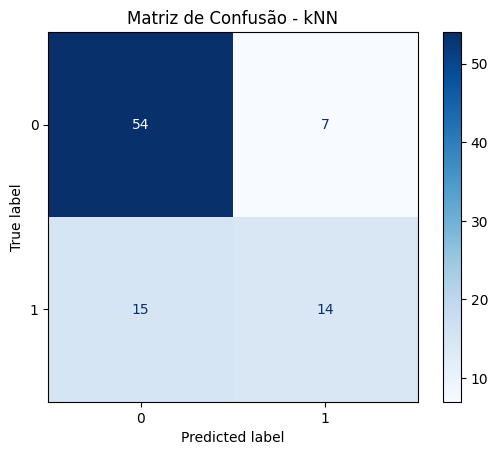

{'Acc teste': 0.7555555555555555,
 'Prec teste': 0.6666666666666666,
 'Recall teste': 0.4827586206896552,
 'F1 teste': 0.56}

In [ ]:
modelo_knn = modelos_classificacao["kNN"]
modelo_knn, metricas_knn, y_pred = avaliar_classificador(
    "kNN",
    modelo_knn,
    X_train,
    X_test,
    y_train,
    y_test,
)
metricas_knn


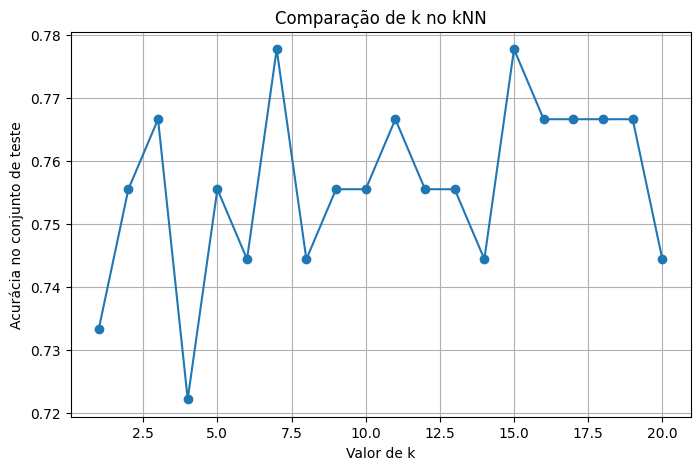

,k,Acc teste
0,1,0.733333
1,2,0.755556
2,3,0.766667
3,4,0.722222
4,5,0.755556
5,6,0.744444
6,7,0.777778
7,8,0.744444
8,9,0.755556
9,10,0.755556


In [ ]:
resultados_k = testar_valores_k(
    X_train, X_test, y_train, y_test,
    preprocessamento, k_min=1, k_max=20,
)
plotar_resultados_k(resultados_k)
display(resultados_k)


### 2.2.3 Aprendizagem Bayesiana (Naive Bayes)


Modelo: Naive Bayes
Acertos = 66
Total   = 90
Acurácia = 0.7333333333333333
              precision    recall  f1-score   support

           0       0.76      0.89      0.82        61
           1       0.63      0.41      0.50        29

    accuracy                           0.73        90
   macro avg       0.70      0.65      0.66        90
weighted avg       0.72      0.73      0.72        90



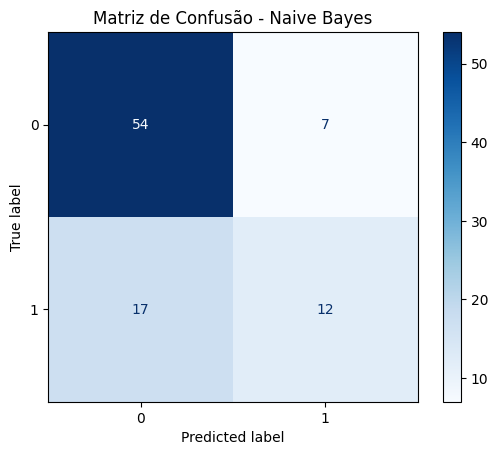

{'Acc teste': 0.7333333333333333,
 'Prec teste': 0.631578947368421,
 'Recall teste': 0.41379310344827586,
 'F1 teste': 0.5}

In [ ]:
modelo_nb = modelos_classificacao["NB"]
modelo_nb, metricas_nb, y_pred = avaliar_classificador(
    "Naive Bayes",
    modelo_nb,
    X_train,
    X_test,
    y_train,
    y_test,
)
metricas_nb


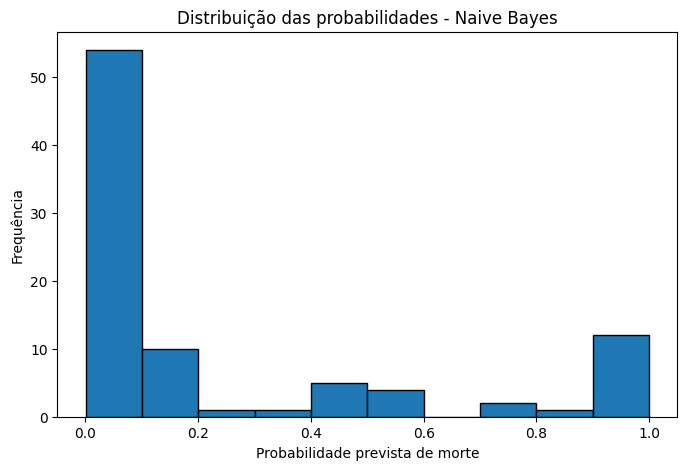

In [ ]:
probabilidades_nb = plotar_distribuicao_probabilidades(
    modelo_nb,
    X_test,
    "Distribuição das probabilidades - Naive Bayes",
)


### 2.2.4 Árvores de decisão


Modelo: Árvore decisão
Acertos = 75
Total   = 90
Acurácia = 0.8333333333333334
              precision    recall  f1-score   support

           0       0.87      0.89      0.88        61
           1       0.75      0.72      0.74        29

    accuracy                           0.83        90
   macro avg       0.81      0.80      0.81        90
weighted avg       0.83      0.83      0.83        90



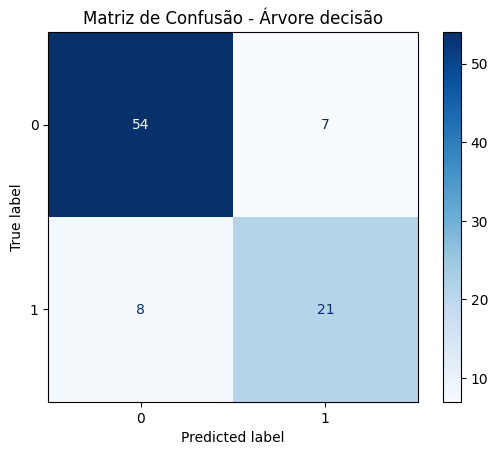

{'Acc teste': 0.8333333333333334,
 'Prec teste': 0.75,
 'Recall teste': 0.7241379310344828,
 'F1 teste': 0.7368421052631579}

In [ ]:
modelo_arvore = modelos_classificacao["Árvore dec"]
modelo_arvore, metricas_arvore, y_pred = avaliar_classificador(
    "Árvore decisão",
    modelo_arvore,
    X_train,
    X_test,
    y_train,
    y_test,
)
metricas_arvore


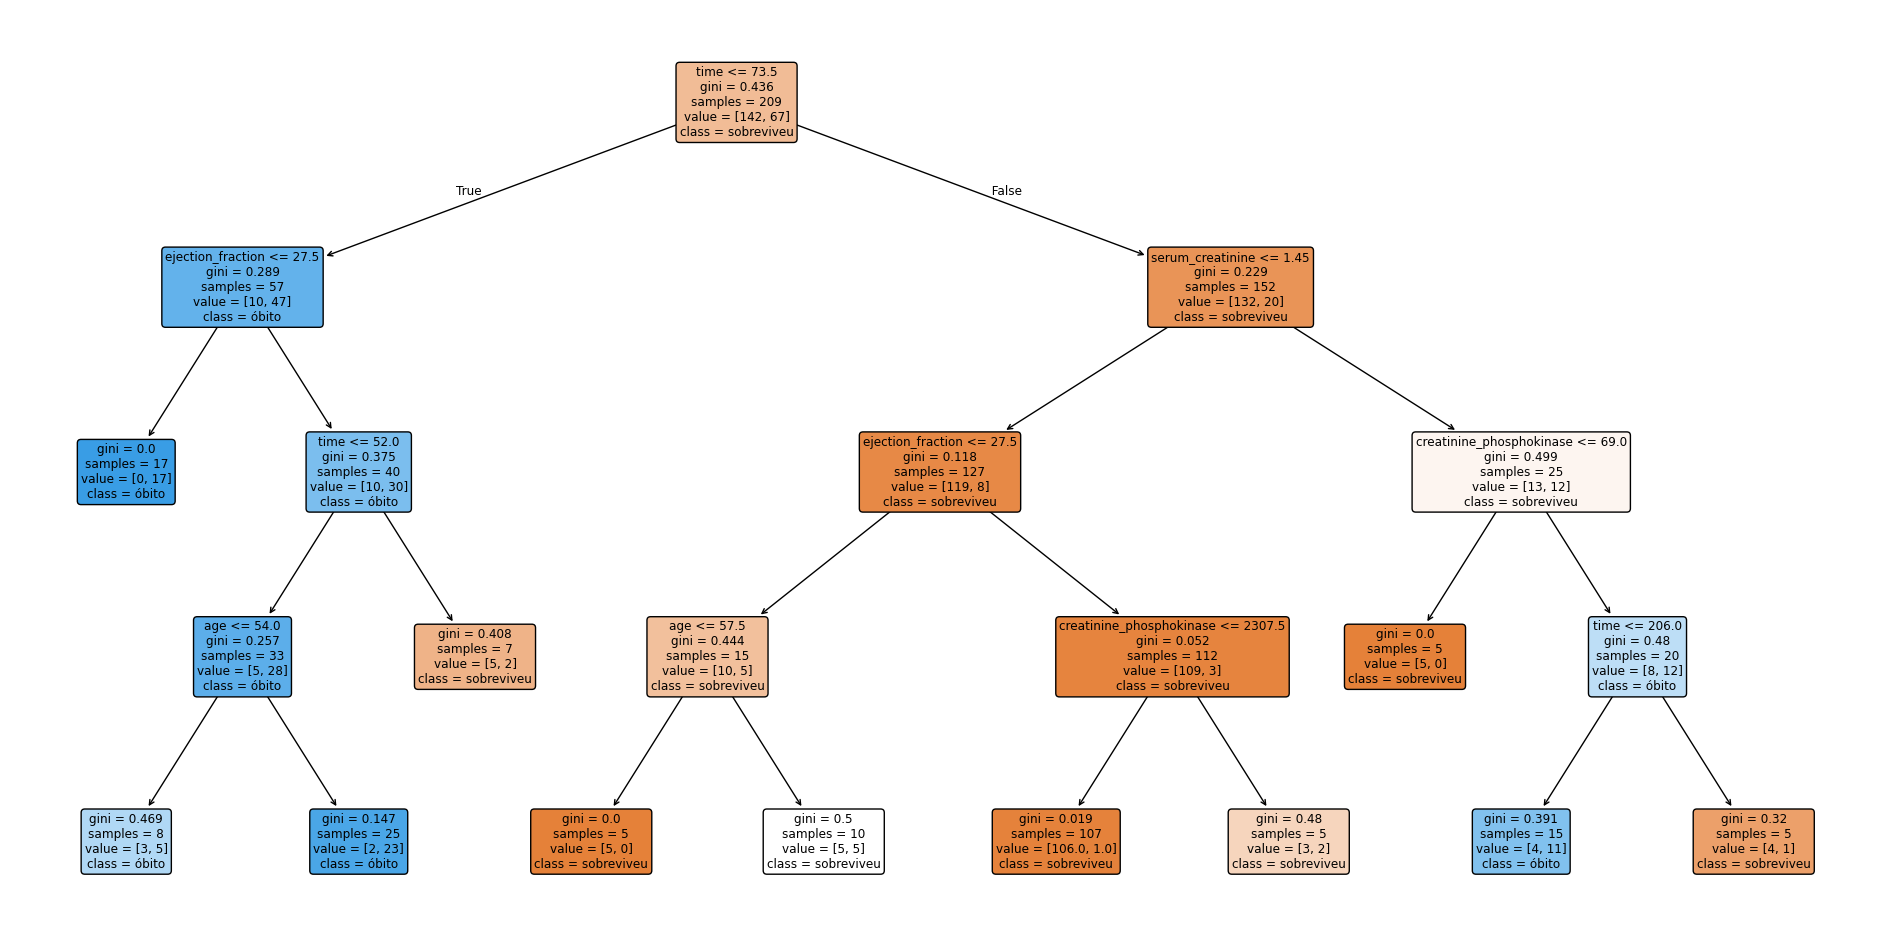

In [ ]:
plt.figure(figsize=(24, 12))
plot_tree(
    modelo_arvore,
    feature_names=features_classificacao,
    class_names=["sobreviveu", "óbito"],
    filled=True,
    rounded=True
)
plt.show()


### 2.2.5 Random Forest


Modelo: Random Forest
Acertos = 73
Total   = 90
Acurácia = 0.8111111111111111
              precision    recall  f1-score   support

           0       0.83      0.90      0.87        61
           1       0.75      0.62      0.68        29

    accuracy                           0.81        90
   macro avg       0.79      0.76      0.77        90
weighted avg       0.81      0.81      0.81        90



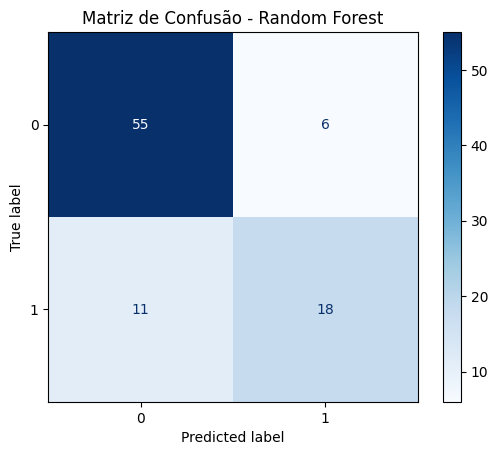

{'Acc teste': 0.8111111111111111,
 'Prec teste': 0.75,
 'Recall teste': 0.6206896551724138,
 'F1 teste': 0.6792452830188679}

In [ ]:
modelo_rf = modelos_classificacao["RF"]
modelo_rf, metricas_rf, y_pred = avaliar_classificador(
    "Random Forest",
    modelo_rf,
    X_train,
    X_test,
    y_train,
    y_test,
)
metricas_rf


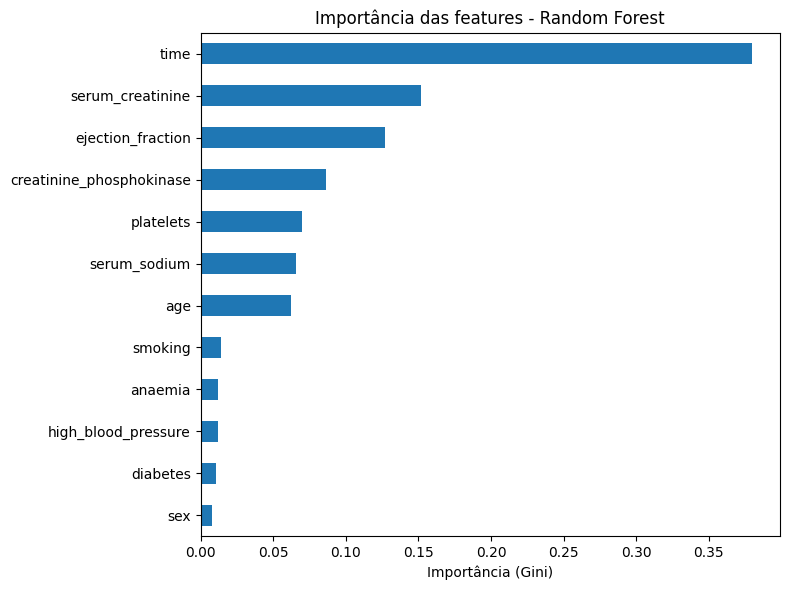

In [ ]:
import pandas as pd

importancias = pd.Series(
    modelo_rf.feature_importances_,
    index=features_classificacao,
).sort_values(ascending=True)

importancias.plot(kind="barh", figsize=(8, 6))
plt.title("Importância das features - Random Forest")
plt.xlabel("Importância (Gini)")
plt.tight_layout()
plt.show()


### 2.2.6 Regressão logística


Modelo: Regressão logística
Acertos = 75
Total   = 90
Acurácia = 0.8333333333333334
              precision    recall  f1-score   support

           0       0.85      0.92      0.88        61
           1       0.79      0.66      0.72        29

    accuracy                           0.83        90
   macro avg       0.82      0.79      0.80        90
weighted avg       0.83      0.83      0.83        90



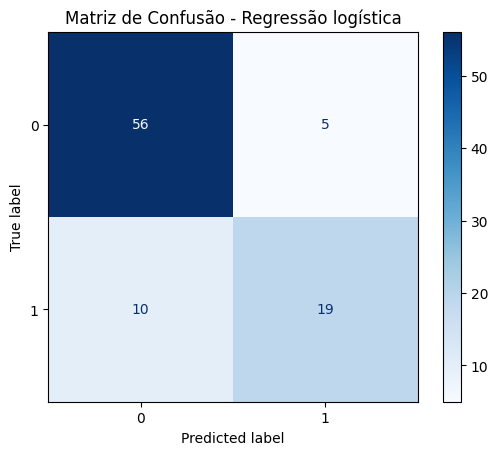

{'Acc teste': 0.8333333333333334,
 'Prec teste': 0.7916666666666666,
 'Recall teste': 0.6551724137931034,
 'F1 teste': 0.7169811320754716}

In [ ]:
modelo_log = modelos_classificacao["Relog"]
modelo_log, metricas_log, y_pred = avaliar_classificador(
    "Regressão logística",
    modelo_log,
    X_train,
    X_test,
    y_train,
    y_test,
)
metricas_log


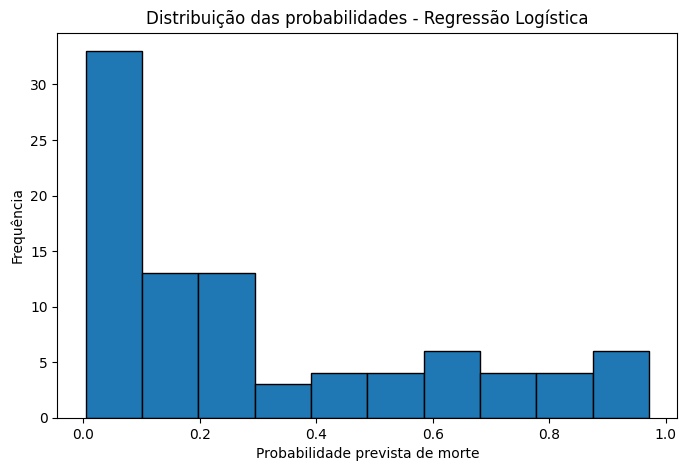

In [ ]:
probabilidades_log = plotar_distribuicao_probabilidades(
    modelo_log,
    X_test,
    "Distribuição das probabilidades - Regressão Logística",
)


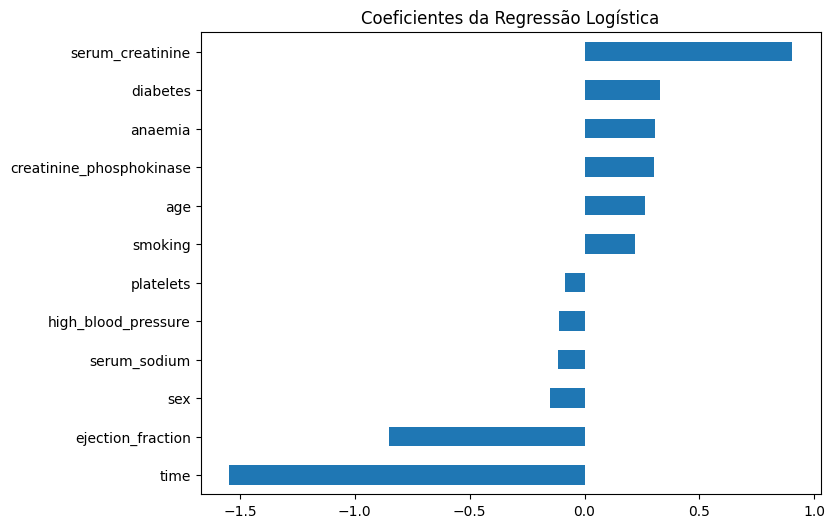

,0
time,-1.548643
ejection_fraction,-0.850949
sex,-0.148305
serum_sodium,-0.116818
high_blood_pressure,-0.111409
platelets,-0.082942
smoking,0.217762
age,0.263429
creatinine_phosphokinase,0.304282
anaemia,0.306530


In [ ]:
coeficientes = plotar_coeficientes_regressao_logistica(
    modelo_log,
    continuous_cols + binary_cols,
)
coeficientes.sort_values()


### 2.2.7 Support Vector Machine (SVM)


Modelo: SVM
Acertos = 67
Total   = 90
Acurácia = 0.7444444444444445
              precision    recall  f1-score   support

           0       0.80      0.84      0.82        61
           1       0.62      0.55      0.58        29

    accuracy                           0.74        90
   macro avg       0.71      0.69      0.70        90
weighted avg       0.74      0.74      0.74        90



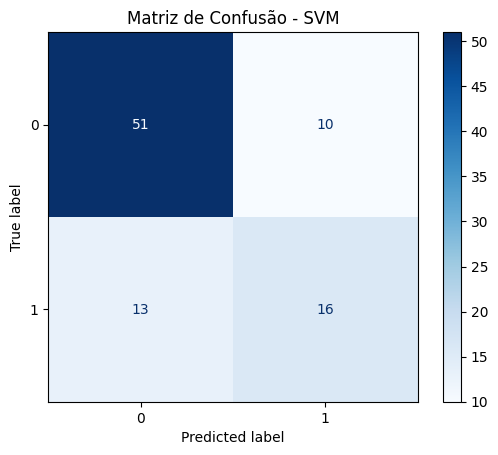

{'Acc teste': 0.7444444444444445,
 'Prec teste': 0.6153846153846154,
 'Recall teste': 0.5517241379310345,
 'F1 teste': 0.5818181818181818}

In [ ]:
modelo_svm = modelos_classificacao["SVM"]
modelo_svm, metricas_svm, y_pred = avaliar_classificador(
    "SVM",
    modelo_svm,
    X_train,
    X_test,
    y_train,
    y_test,
)
metricas_svm


### 2.2.8 Comparação com ajuste de hiperparâmetros


In [ ]:
parametros_grid = {
    "kNN": {
        "modelo__n_neighbors": [3, 5, 7, 9, 11],
        "modelo__weights": ["uniform", "distance"],
    },
    "NB": {
        "modelo__var_smoothing": [1e-9, 1e-8, 1e-7, 1e-6],
    },
    "Árvore dec": {
        "max_depth": [2, 3, 4, 5, None],
        "min_samples_leaf": [1, 3, 5, 10],
        "criterion": ["gini", "entropy"],
    },
    "Relog": {
        "modelo__C": [0.01, 0.1, 1, 10, 100],
        "modelo__class_weight": [None, "balanced"],
    },
    "SVM": {
        "modelo__C": [0.1, 1, 10, 100],
        "modelo__gamma": ["scale", 0.01, 0.1, 1],
        "modelo__class_weight": [None, "balanced"],
    },
    "RF": {
        "n_estimators": [100, 200],
        "max_depth": [None, 5, 10],
        "min_samples_leaf": [1, 3, 5],
        "class_weight": [None, "balanced"],
    },
}

(
    resultados_tuning,
    melhores_modelos,
    melhor_modelo_tunado_nome,
    melhor_modelo_tunado,
) = buscar_melhores_modelos(
    modelos_classificacao,
    parametros_grid,
    X_train,
    X_test,
    y_train,
    y_test,
    cv,
)

resultados_tuning


,Modelo,Melhor F1 CV,Acc teste,Prec teste,Recall teste,F1 teste,Melhores parâmetros
0,RF,0.780378,0.833333,0.750000,0.724138,0.736842,"{'class_weight': 'balanced', 'max_depth': None..."
1,Relog,0.720493,0.800000,0.657143,0.793103,0.718750,"{'modelo__C': 0.01, 'modelo__class_weight': 'b..."
2,Árvore dec,0.711579,0.844444,0.941176,0.551724,0.695652,"{'criterion': 'entropy', 'max_depth': 4, 'min_..."
3,SVM,0.726508,0.766667,0.633333,0.655172,0.644068,"{'modelo__C': 1, 'modelo__class_weight': 'bala..."
4,kNN,0.560458,0.766667,0.700000,0.482759,0.571429,"{'modelo__n_neighbors': 3, 'modelo__weights': ..."
5,NB,0.521934,0.733333,0.631579,0.413793,0.500000,{'modelo__var_smoothing': 1e-09}


### 2.2.9 Conclusão da classificação


In [ ]:
print("Melhor modelo sem tuning pelo F1 no teste:", melhor_modelo_nome)
print("Melhor modelo com tuning pelo F1 no teste:", melhor_modelo_tunado_nome)

display(resultados_modelos)
display(resultados_tuning)


Melhor modelo sem tuning pelo F1 no teste: Árvore dec
Melhor modelo com tuning pelo F1 no teste: RF


,Modelo,Acc CV,Prec CV,Recall CV,F1 CV,Acc teste,Prec teste,Recall teste,F1 teste
0,Árvore dec,0.770499,0.647560,0.717582,0.666593,0.833333,0.750000,0.724138,0.736842
1,Relog,0.813705,0.744322,0.656044,0.687683,0.833333,0.791667,0.655172,0.716981
2,RF,0.851800,0.798009,0.731868,0.759130,0.811111,0.750000,0.620690,0.679245
3,SVM,0.794309,0.696093,0.671429,0.677891,0.744444,0.615385,0.551724,0.581818
4,kNN,0.765621,0.734127,0.417582,0.531263,0.755556,0.666667,0.482759,0.560000
5,NB,0.765854,0.733413,0.417582,0.521934,0.733333,0.631579,0.413793,0.500000


,Modelo,Melhor F1 CV,Acc teste,Prec teste,Recall teste,F1 teste,Melhores parâmetros
0,RF,0.780378,0.833333,0.750000,0.724138,0.736842,"{'class_weight': 'balanced', 'max_depth': None..."
1,Relog,0.720493,0.800000,0.657143,0.793103,0.718750,"{'modelo__C': 0.01, 'modelo__class_weight': 'b..."
2,Árvore dec,0.711579,0.844444,0.941176,0.551724,0.695652,"{'criterion': 'entropy', 'max_depth': 4, 'min_..."
3,SVM,0.726508,0.766667,0.633333,0.655172,0.644068,"{'modelo__C': 1, 'modelo__class_weight': 'bala..."
4,kNN,0.560458,0.766667,0.700000,0.482759,0.571429,"{'modelo__n_neighbors': 3, 'modelo__weights': ..."
5,NB,0.521934,0.733333,0.631579,0.413793,0.500000,{'modelo__var_smoothing': 1e-09}


### 2.2.10 Comparação visual final


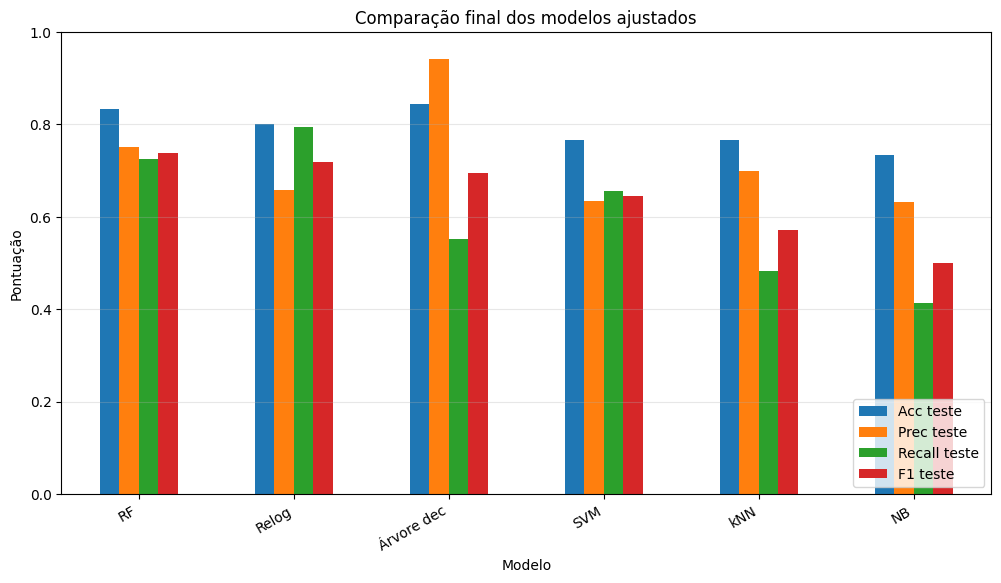

,Acc teste,Prec teste,Recall teste,F1 teste
Modelo,,,,
RF,0.833333,0.750000,0.724138,0.736842
Relog,0.800000,0.657143,0.793103,0.718750
Árvore dec,0.844444,0.941176,0.551724,0.695652
SVM,0.766667,0.633333,0.655172,0.644068
kNN,0.766667,0.700000,0.482759,0.571429
NB,0.733333,0.631579,0.413793,0.500000


In [ ]:
metricas_finais = plotar_metricas_modelos(
    resultados_tuning,
    ["Acc teste", "Prec teste", "Recall teste", "F1 teste"],
    "Comparação final dos modelos ajustados",
)

metricas_finais


# **Interpretação dos Resultados da Classificação**

## **1. Melhor Modelo Identificado**
- **Sem ajuste de hiperparâmetros:** Árvore de Decisão (F1 = 0.737)
- **Com ajuste de hiperparâmetros:** Random Forest (F1 = 0.737)

Ambos alcançam desempenho semelhante, mas o Random Forest com ajuste nos hiperparâmetros apresenta melhor generalização.

## **2. Análise das Métricas Finais**

| Métrica | Random Forest | Regressão Logística | Árvore de Decisão | SVM | kNN | Naive Bayes |
|---------|---------------|-------------------|-------------------|-----|-----|-------------|
| **Acurácia** | 0.833 | 0.800 | 0.844 | 0.767 | 0.767 | 0.733 |
| **Precisão** | 0.750 | 0.657 | 0.941 | 0.633 | 0.700 | 0.632 |
| **Recall** | 0.724 | 0.793 | 0.552 | 0.655 | 0.483 | 0.414 |
| **F1** | 0.737 | 0.719 | 0.696 | 0.644 | 0.571 | 0.500 |

## **3. Interpretação por Modelo**

**1. Random Forest**
- F1-score: 0.737 (melhor equilibrio entre precisão e recall)
- Acurácia: 83.3%
- Identifica corretamente 72.4% dos óbitos (recall alto)
- Quando prediz óbito, acerta 75% das vezes (precisão)

**2. Regressão Logística**
- F1-score: 0.719
- Melhor recall (79.3%) - identifica mais óbitos
- Menor precisão (65.7%) - mais falsos positivos
- Ótima para cenários onde perder um óbito é custoso

**3. Árvore de Decisão**
- F1-score: 0.696
- Melhor precisão (94.1%) - poucos falsos positivos
- Recall baixo (55.2%) - deixa passar muitos óbitos
- Interpretável, mas menos balanceado

## **4. Características Mais Importantes (Random Forest)**

Ranqueadas por importância:
1. **time** (0.380) - Período de acompanhamento
2. **serum_creatinine** (0.152) - Nível de creatinina no sangue
3. **ejection_fraction** (0.127) - Porcentagem de sangue que sai do coração a cada contração
4. **creatinine_phosphokinase** (0.087) - Nível da enzima CPK no sangue
5. **platelets** (0.070) - Quantidade de plaquetas no sangue
6. **serum_sodium** (0.066) - Nível de sódio no sangue

## **5. Coeficientes da Regressão Logística (Direção do Risco)**

**Aumentam risco de morte (coeficientes positivos):**
- serum_creatinine (+0.905) - Forte indicador
- creatinine_phosphokinase (+0.304)
- diabetes (+0.327)
- anaemia (+0.307)

**Reduzem risco de morte (coeficientes negativos):**
- time (-1.549) - Quanto maior o acompanhamento, menor o risco
- ejection_fraction (-0.851) - Quanto mais sangue sair do coração a cada contração, melhor

## **6. Recomendações Clínicas**

**Para monitoramento clínico:**
1. Focar em pacientes com **serum_creatinine** elevado
2. Acompanhar a **ejection_fraction** como fator protetor
3. Período de **time** crítico nas primeiras semanas

**Para modelo em produção:**
- Use **Random Forest** ou **Regressão Logística** conforme necessidade:
    - **RF**: melhor F1-score geral
    - **Log Reg**: melhor identificação de casos em risco (recall)

## **7. Distribuição de Probabilidades**

- **Naive Bayes**: Distribuição muito concentrada (0 e 1)
- **Regressão Logística**: Distribuição bem separada, mais calibrada

A Regressão Logística produz probabilidades mais confiáveis para tomada de decisão clínica.

## **8. Desafio do Conjunto de Dados**

- **Desbalanceamento:** 32.4% óbitos vs 67.6% sobreviventes
- **Tamanho pequeno:** 299 registros (90 no teste)
- **Solução aplicada:** `class_weight='balanced'` nos modelos